# (WIP) IIR développement

In [1]:
# import
import matplotlib.pyplot as plt; from scipy.io import wavfile
%run ./init.py

## Comment trouver les coefficients d'un FIR?

Soit le filtre FIR : $ y[n] = b_0x[n] + b_1x[n-1] $

Sa réponse en fréquence est : $ H(w) = Y(w) / X(w) = b_0 + b_1.e^{-jw} $  

Calcul de son gain (module): 

$ H(w) = b_0 + b_1.cos(w) - j.b_1.sin(w) $

$ |H(w)| = \sqrt{[b_0+b_1cos(w)]^2 + [b_1sin(w)]^2} = \sqrt{b_0^2 + b_1^2 + 2b_0b_1cos(w)}$

en basse fréquence ($f = 0$ ou $w = 0$) on a $|H(0) = \sqrt{(b0 + b1)^2}$  
en haute fréquence ($f = Fs/2$ ou $w = \pi$) on a $|H(\pi) = \sqrt{(b0 - b1)^2}$

soit un **passe bas** si $b0 = b1$ et un **passe haut** si $b0 = -b1$.

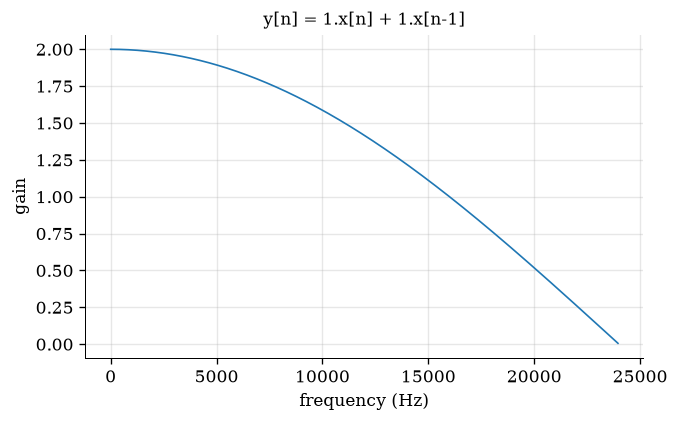

In [2]:
# create filter
# b = [1, -1]; a = [1] # high pass
b = [1, 1]; a = [1] # low pass

# charaterise filter
freqs, H = scipy.signal.freqz(b, a, fs=fs)

# plot
plt.plot(freqs, np.abs(H))
plt.xlabel('frequency (Hz)'); plt.ylabel('gain'); 
plt.title(filter_formula(b, a)); 
plt.show()

Soit le filtre FIR : $ y[n] = b_0.x[n] + b_1.x[n-1] - a_1.y[n-1]$

Sa réponse impulsionnelle est : $ H(w) = (b_0 + b_1.e^{-jw}) / (1+a_1.e^{-jw}) $

Le module d'une fraction c'est la fraction des modules:

$ |H(w)| = \sqrt{b_0^2+b_1^2+2b_0b_1cos(w)} / \sqrt{1 + a_1^2 + 2a_1cos(w)} $

$|H(0) = |b_0 + b_1|/|1+a_1|$

$|H(\pi) = |b_0 - b_1|/|1-a_1|$

comme le filtre précédent, avec a qui contrôle la steepneess.

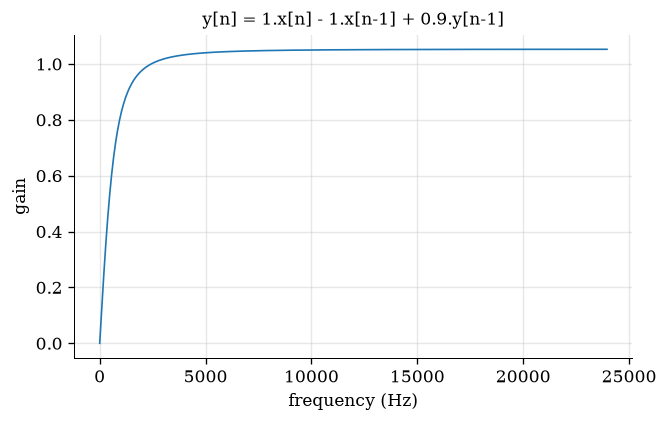

In [3]:
# create filter
# a = [1, 0] # no feedback
# a = [1, 0.9] # denominator: gain in high
a = [1, -0.9] # denominator: gain in low
b = [1, -1]; # nominator: high pass
# b = [1, 1]; # nominator: low pass

# charaterise filter
freqs, H = scipy.signal.freqz(b, a, fs=fs)

# plot
plt.plot(freqs, np.abs(H))
plt.xlabel('frequency (Hz)'); plt.ylabel('gain'); 
plt.title(filter_formula(b, a)); 
plt.show()

un autre filtre (justify uses of z plane to search for poles near but not on the unit circle)

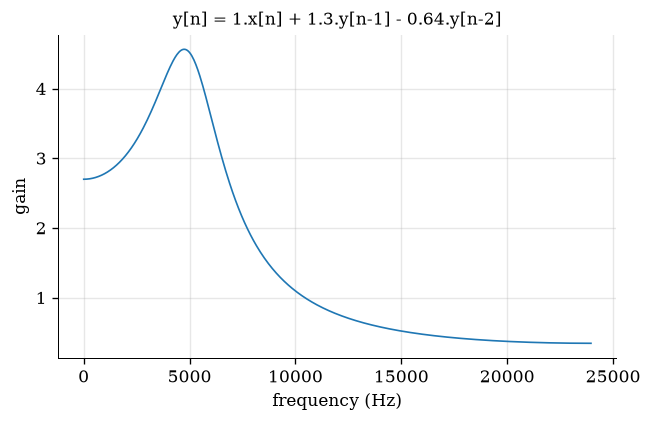

In [4]:
# create filter
r = 0.1
f1 = 5000 # peak frequency
w0 = (f1/fs) * 2*math.pi; 
r = 0.8 # selectivity (|r| < 1)
b = [1]; a = [1, -2*r*math.cos(w0), r**2]

# charaterise filter
freqs, H = scipy.signal.freqz(b, a, fs=fs)

# plot
plt.plot(freqs, np.abs(H))
plt.xlabel('frequency (Hz)'); plt.ylabel('gain'); 
# plt.xscale('log')
plt.title(filter_formula(b, a)); 
plt.show()

## Bases de la Transformée en Z

- comment obtenir les coefficients d'un filtre simple, d'un biquad
- tous les filtres peuvent être assemblés à partir de sommes de biquads
- on peut donc faire tous les filtres

I’d show poles/zeros interactively, establish “poles near unit circle → resonance / zeros near unit circle → attenuation / outside unit circle → instability”, and stop there.

## Interactive exploration Z plane 

Pour se faire une meilleur idée, on manipule les zéros et les pôles :

https://dsp-workshop.nl/basics/pole-zero-explorer.html

## Application de la transformée en Z pour calculer les coefficients d'un filtre

Not sure we want to go that deep.

In [5]:
# %matplotlib widget
# # import matplotlib.pyplot as plt
# # import numpy as np
# from matplotlib.widgets import Slider

# # 1. Generate initial data
# t = np.linspace(0, 1, 1000)
# initial_frequency = 5
# y = np.sin(2 * np.pi * initial_frequency * t)

# # 2. Create the figure and layout
# # Adjust the bottom margin to leave room for the slider
# fig, ax = plt.subplots()
# plt.subplots_adjust(bottom=0.25)

# # 3. Plot the initial line
# # We capture the line object (line,) so we can update its data later
# (line,) = ax.plot(t, y, lw=2)
# ax.set_xlabel("Time (s)")
# ax.set_ylabel("Amplitude")
# ax.set_title("Interactive Sine Wave")

# # 4. Create the slider axes and the slider widget
# # Position syntax: [left, bottom, width, height]
# ax_slider = plt.axes([0.25, 0.1, 0.65, 0.03])
# freq_slider = Slider(
#     ax=ax_slider,
#     label="Frequency",
#     valmin=0.1,
#     valmax=30.0,
#     valinit=initial_frequency,
# )


# # 5. Define the update function
# # This function triggers whenever the slider moves
# def update(val):
#     # Get the current value from the slider
#     freq = freq_slider.val
#     # Recalculate y data
#     new_y = np.sin(2 * np.pi * freq * t)
#     # Update the line data
#     line.set_ydata(new_y)
#     # Redraw the canvas to show the changes
#     fig.canvas.draw_idle()


# # 6. Link the slider to the update function
# freq_slider.on_changed(update)

# plt.show()

## Retard d'un IIR

En utilisant `filtfilt` on peut même éviter le retard lié à l'application d'un filtre, au prix d'appliquer le filtre 2 fois (pas utilisable en temps-réel: filtre non-causal).

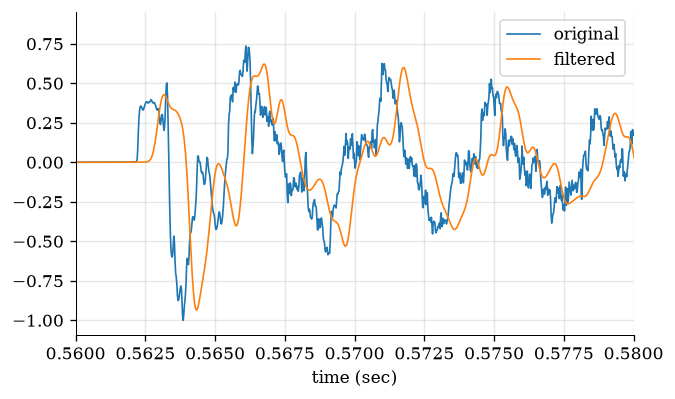

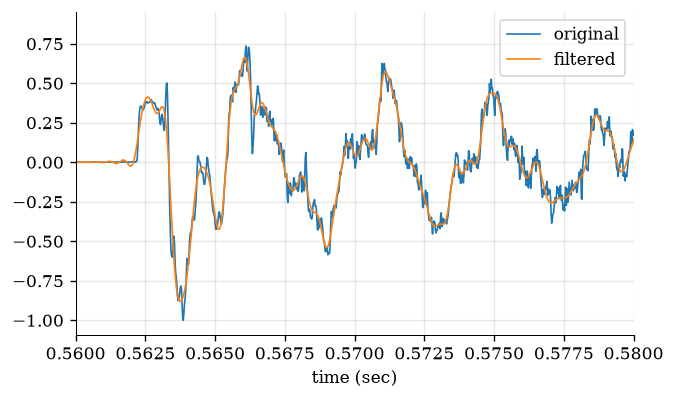

In [9]:
# load audio file
audio_in, fs = wavread('../assets/drums.wav')

# get filter coefficients
b, a = scipy.signal.iirfilter(N=12, Wn=2000, fs=fs, btype='low', ftype='butter')

# filter signal 
audio_out = scipy.signal.lfilter(b, a, audio_in)

# plot
t = np.arange(0, len(audio_in))/fs
plt.plot(t, audio_in, label = 'original');
plt.plot(t, audio_out, label = 'filtered');
plt.xlim([0.56, 0.58]); plt.legend(); plt.xlabel('time (sec)'); plt.show()

# apply filter forward and backward using filtfilt
audio_out = scipy.signal.filtfilt(b, a, audio_in)

# plot
t = np.arange(0, len(audio_in))/fs
plt.plot(t, audio_in, label = 'original');
plt.plot(t, audio_out, label = 'filtered');
plt.xlim([0.56, 0.58]); plt.legend(); plt.xlabel('time (sec)'); plt.show()